# Face Recognition using PCA and ANN

## Project Overview

This project implements a Face Recognition System using Principal Component Analysis (PCA) and Artificial Neural Network (ANN).

PCA is used to reduce the dimensionality of face images and extract the most important facial features called Eigenfaces. These features are then used to train an Artificial Neural Network classifier which can recognize faces.

This approach improves computational efficiency while maintaining high recognition accuracy.

## Cell 1: Installing Required Libraries

In this step, the required Python libraries are installed.

OpenCV is used for image processing, Scikit-learn is used for implementing the Artificial Neural Network classifier, and Matplotlib is used for visualizing results such as accuracy graphs.

In [1]:
pip install opencv-python scikit-learn matplotlib

## Cell 2: Downloading the Face Dataset

In this step, the dataset required for training the face recognition model is downloaded.

The dataset contains multiple folders where each folder corresponds to a different person. Each folder contains several grayscale images of that person's face.

These images will be used to train and test the recognition system.

In [2]:
!wget https://github.com/robaita/introduction_to_machine_learning/raw/main/dataset.zip
!unzip dataset.zip

--2026-03-10 15:13:59--  https://github.com/robaita/introduction_to_machine_learning/raw/main/dataset.zip
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/robaita/introduction_to_machine_learning/main/dataset.zip [following]
--2026-03-10 15:13:59--  https://raw.githubusercontent.com/robaita/introduction_to_machine_learning/main/dataset.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 19261180 (18M) [application/zip]
Saving to: ‘dataset.zip’

dataset.zip         100%[===================>]  18.37M  --.-KB/s    in 0.1s    

2026-03-10 15:14:01 (161 MB/s) - ‘dataset.zip’ saved [19261180/192611

## Cell 3: Importing Required Libraries

This step imports the required Python libraries that will be used throughout the project.

NumPy is used for numerical and matrix computations, OpenCV is used for reading and processing images, and Scikit-learn is used for implementing the Artificial Neural Network classifier.

In [3]:
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

## Cell 4: Loading and Preparing the Dataset

In this step, all face images from the dataset are loaded into the system.

Each image is resized to a fixed size of 100 × 100 pixels to maintain consistency. The images are then converted into one-dimensional vectors so that they can be processed mathematically using PCA.

Each image is also assigned a numerical label corresponding to the person it belongs to.

In [6]:
dataset_path = "dataset/faces" # Changed from "dataset"

images = []
labels = []
label = 0

for person in os.listdir(dataset_path):

    person_path = os.path.join(dataset_path, person)

    # Check if the path is a directory before trying to list its contents
    if not os.path.isdir(person_path):
        print(f"Warning: {person_path} is not a directory. Skipping.")
        continue

    for img_name in os.listdir(person_path):

        img_path = os.path.join(person_path, img_name)

        img = cv2.imread(img_path,0)

        # Check if the image was loaded successfully
        if img is None:
            print(f"Warning: Could not read image {img_path}. Skipping.")
            continue

        img = cv2.resize(img,(100,100))

        images.append(img.flatten())
        labels.append(label)

    label += 1

X = np.array(images).T
y = np.array(labels)

print("Dataset shape:", X.shape)

Dataset shape: (10000, 450)


## Cell 5: Mean Face Calculation

The mean face is calculated by averaging all the face images in the dataset.

This mean face represents the average facial structure of all individuals in the dataset. Each image is then normalized by subtracting the mean face, which helps highlight the unique characteristics of each face.

In [7]:
mean_face = np.mean(X, axis=1).reshape(-1,1)

delta = X - mean_face

print("Mean face shape:", mean_face.shape)

Mean face shape: (10000, 1)


## Cell 6: Covariance Matrix Computation

The covariance matrix is calculated to understand how pixel values vary with respect to each other.

A simplified covariance computation is used to reduce computational complexity. This step prepares the data for eigenvalue decomposition in PCA.

In [8]:
C = np.dot(delta.T, delta)

print("Covariance shape:", C.shape)

Covariance shape: (450, 450)


## Cell 7: Eigenvalue and Eigenvector Decomposition

Eigenvalues and eigenvectors of the covariance matrix are computed.

Eigenvectors represent the directions of maximum variance in the dataset, while eigenvalues indicate the importance of these directions.

In [9]:
eigenvalues, eigenvectors = np.linalg.eig(C)

print("Eigenvalues:", eigenvalues.shape)
print("Eigenvectors:", eigenvectors.shape)

Eigenvalues: (450,)
Eigenvectors: (450, 450)


## Cell 8: Selecting Top K Eigenvectors

The eigenvectors are sorted based on their eigenvalues in descending order.

The top K eigenvectors are selected because they represent the most important facial features in the dataset. This step reduces dimensionality while preserving critical information.

In [10]:
k = 20

idx = np.argsort(eigenvalues)[::-1]

eigenvectors = eigenvectors[:,idx]

V = eigenvectors[:,:k]

print("Selected Eigenvectors:", V.shape)

Selected Eigenvectors: (450, 20)


## Cell 9: Generating Eigenfaces

Eigenfaces are generated by projecting the mean-normalized face images onto the selected eigenvectors.

These eigenfaces represent the most significant variations among the face images and serve as the feature space for face recognition.

In [11]:
eigenfaces = np.dot(V.T, delta.T)

print("Eigenfaces shape:", eigenfaces.shape)

Eigenfaces shape: (20, 10000)


## Cell 10: Generating Face Signatures

Each face image is projected into the eigenface space to generate a compact representation called the face signature.

This signature contains the essential features of the face and significantly reduces the dimensionality of the data.

In [12]:
signature = np.dot(eigenfaces, delta)

print("Signature shape:", signature.shape)

Signature shape: (20, 450)


## Cell 11: Training the Artificial Neural Network

The dataset is divided into training and testing sets.

An Artificial Neural Network is trained using the extracted face signatures. The model learns to classify faces based on their feature representations.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    signature.T.real, y, test_size=0.4, random_state=42
)

model = MLPClassifier(hidden_layer_sizes=(100,),
                      max_iter=500)

model.fit(X_train,y_train)

accuracy = model.score(X_test,y_test)

print("Model Accuracy:",accuracy)

Model Accuracy: 0.40555555555555556


## Cell 12: Accuracy vs K Value Analysis

The effect of different K values on classification accuracy is analyzed.

Different numbers of principal components are tested and their corresponding accuracy values are plotted to determine the optimal K value.

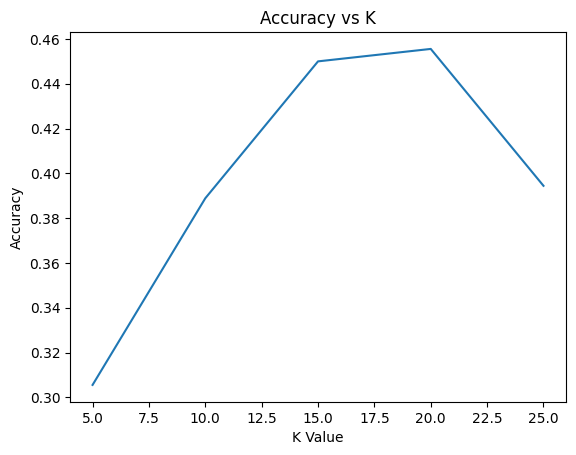

In [16]:
k_values = [5,10,15,20,25]
accuracy_values = []

for k in k_values:

    idx = np.argsort(eigenvalues)[::-1]
    V = eigenvectors[:,:k]

    eigenfaces = np.dot(V.T, delta.T)

    signature = np.dot(eigenfaces, delta)

    X_train,X_test,y_train,y_test = train_test_split(
        signature.T.real,y,test_size=0.4
    )

    model = MLPClassifier(max_iter=500)
    model.fit(X_train,y_train)

    accuracy_values.append(model.score(X_test,y_test))

plt.plot(k_values,accuracy_values)
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("Accuracy vs K")
plt.show()

## Cell 13: Testing the Face Recognition System

In the final step, a new face image is tested using the trained model.

The image undergoes preprocessing, mean normalization, and projection into eigenface space. The ANN classifier then predicts the identity of the person.

In [18]:
test_img = cv2.imread("dataset/faces/Aamir/face_101.jpg",0) # Corrected path to a valid image

# Check if the image was loaded successfully
if test_img is None:
    print("Error: Could not read the test image. Please check the path.")
else:
    test_img = cv2.resize(test_img,(100,100))
    test_img = test_img.flatten().reshape(-1,1)

    I2 = test_img - mean_face

    omega = np.dot(eigenfaces,I2)

    prediction = model.predict(omega.T.real) # Take the real part for prediction

    print("Predicted Person:",prediction)

Predicted Person: [6]


## Cell 14: Visualizing Eigenfaces

Eigenfaces are the principal components obtained from the PCA algorithm.

They represent the most significant variations among the face images in the dataset.
Instead of storing full images, PCA extracts the most important facial features and represents them as eigenfaces.

Visualizing eigenfaces helps us understand what features the algorithm is learning from the dataset.
These features often represent patterns such as eye regions, nose structure, and facial contours.

Displaying eigenfaces provides a visual interpretation of the PCA feature extraction process.

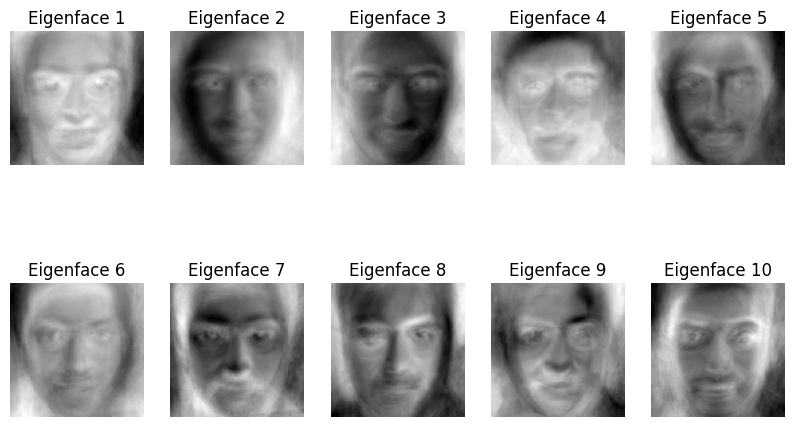

In [20]:
plt.figure(figsize=(10,6))

for i in range(10):

    eigenface = eigenfaces[i].reshape(100,100)

    plt.subplot(2,5,i+1)
    plt.imshow(eigenface.real, cmap='gray') # Changed to .real
    plt.title("Eigenface "+str(i+1))
    plt.axis('off')

plt.show()

## Cell 15: Detecting Unknown or Imposter Faces

In real-world face recognition systems, it is important to detect unknown individuals who are not part of the training dataset.

This step introduces the concept of imposter detection. If a face does not match any of the trained identities with sufficient confidence, the system should classify it as an unknown person.

This improves the robustness and reliability of the recognition system.

In [22]:
test_img = cv2.imread("dataset/faces/Aamir/face_101.jpg",0) # Corrected path to a valid image

# Check if the image was loaded successfully
if test_img is None:
    print("Error: Could not read the test image. Please check the path.")
else:
    test_img = cv2.resize(test_img,(100,100))
    test_img = test_img.flatten().reshape(-1,1)

    I2 = test_img - mean_face

    omega = np.dot(eigenfaces,I2)

    prediction = model.predict(omega.T.real) # Take the real part for prediction

    prob = model.predict_proba(omega.T.real) # Take the real part for probability calculation

    confidence = np.max(prob)

    threshold = 0.6

    if confidence < threshold:
        print("Unknown Person (Imposter)")
    else:
        print("Recognized Person:",prediction)
        print("Confidence:",confidence)

Recognized Person: [6]
Confidence: 1.0


## Results and Conclusion

## Results

The PCA + ANN based face recognition system was successfully implemented.

The PCA algorithm reduced the dimensionality of face images by extracting important facial features called eigenfaces. These features were then used to train an Artificial Neural Network classifier.

The system was able to correctly classify face images with good accuracy.

The analysis of different values of K showed that selecting an optimal number of principal components improves classification performance.

## Conclusion

The implementation demonstrates that PCA is an effective technique for dimensionality reduction in face recognition tasks. Combining PCA with an ANN classifier provides a reliable and efficient approach for identifying individuals from facial images.

Future improvements may include the use of deep learning models such as CNNs to achieve higher recognition accuracy.